In [1]:
import os, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd

here = Path.cwd()
PROJECT_DIR = here.parent if here.name == 'notebooks' else here
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from freight_lib import (find, Cleaner, flag_corrupted, score, Hybrid, Blend,
                         TARGET, FOLDS)

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)

def resolve_data_dir() -> Path:
    if 'DATA_DIR' in os.environ and Path(os.environ['DATA_DIR']).is_dir():
        return Path(os.environ['DATA_DIR'])
    for candidate in [PROJECT_DIR / 'data', here / 'data', Path.home() / 'Downloads']:
        if candidate.is_dir() and any(candidate.glob('*train*.csv')):
            return candidate
    return PROJECT_DIR / 'data'

DATA_DIR = resolve_data_dir()

train = pd.read_csv(find(DATA_DIR, 'train_test'), parse_dates=['date'])
val = pd.read_csv(find(DATA_DIR, 'validation'), parse_dates=['date'])
dec = pd.read_csv(find(DATA_DIR, 'december_chart_inputs'), parse_dates=['date'])

# market_index is one number per day; features only, no labels, so no leakage
market_by_day = pd.concat([train, val]).groupby('date')['market_index'].median()

cleaner = Cleaner().fit(train)
tr = cleaner.transform(train, market_by_day)
tr['is_corrupted'] = flag_corrupted(tr)
print('Cleaned rows:', len(tr), '| Corrupted rows flagged:', tr['is_corrupted'].sum())


Corrupted rows: 677


In [2]:
print("market_index range  train:", tr["market_index"].min().round(3), "to", tr["market_index"].max().round(3))
print("market_index range  validation:", val["market_index"].min().round(3), "to", val["market_index"].max().round(3))
print()
print("Average market_index by month:")
print(market_by_day.resample("MS").mean().round(3).to_string())

market_index range  train: 0.676 to 1.468
market_index range  validation: 0.724 to 1.099

Average market_index by month:
date
2025-01-01    0.927
2025-02-01    0.998
2025-03-01    1.074
2025-04-01    1.209
2025-05-01    1.300
2025-06-01    1.280
2025-07-01    1.200
2025-08-01    0.980
2025-09-01    0.893
2025-10-01    0.956
2025-11-01    0.919
2025-12-01    0.935
Freq: MS


In [3]:
def run_folds(build_model, drop_corrupted=True):
    """Returns WAPE per fold, the mean, and the worst fold."""
    rows = []
    for fold, (start, end) in FOLDS.items():
        past = tr[tr["date"] < start]
        if drop_corrupted:
            past = past[~past["is_corrupted"]]
        future = tr[(tr["date"] >= start) & (tr["date"] <= end) & ~tr["is_corrupted"]]
        pred = build_model().fit(past).predict(future)
        rows.append({"fold": fold, **score(future[TARGET], pred)})
    out = pd.DataFrame(rows)
    return {"per_fold_WAPE": out["WAPE"].round(2).tolist(),
            "mean_WAPE": round(out["WAPE"].mean(), 2),
            "worst_WAPE": round(out["WAPE"].max(), 2)}

WITH_TIME = ["log_dist", "market", "t"]
NO_TIME = ["log_dist", "market"]

In [4]:
print("--- Ridge penalty (alpha) ---")
for alpha in [0.1, 1, 10, 100, 1000]:
    print("alpha", alpha, run_folds(lambda: Hybrid(WITH_TIME, alpha=alpha)))

print("\n--- GBM size ---")
for leaves, min_leaf in [(7, 100), (15, 50), (31, 50), (15, 200)]:
    params = dict(num_leaves=leaves, min_child_samples=min_leaf)
    print(f"leaves={leaves}, min_leaf={min_leaf}",
          run_folds(lambda: Hybrid(WITH_TIME, gbm_params=params)))

--- Ridge penalty (alpha) ---
alpha 0.1 {'per_fold_WAPE': [4.68, 2.51, 2.56, 2.21], 'mean_WAPE': np.float64(2.99), 'worst_WAPE': np.float64(4.68)}
alpha 1 {'per_fold_WAPE': [4.68, 2.51, 2.56, 2.21], 'mean_WAPE': np.float64(2.99), 'worst_WAPE': np.float64(4.68)}
alpha 10 {'per_fold_WAPE': [4.68, 2.51, 2.56, 2.21], 'mean_WAPE': np.float64(2.99), 'worst_WAPE': np.float64(4.68)}
alpha 100 {'per_fold_WAPE': [4.65, 2.51, 2.56, 2.21], 'mean_WAPE': np.float64(2.98), 'worst_WAPE': np.float64(4.65)}
alpha 1000 {'per_fold_WAPE': [4.37, 2.52, 2.54, 2.21], 'mean_WAPE': np.float64(2.91), 'worst_WAPE': np.float64(4.37)}

--- GBM size ---
leaves=7, min_leaf=100 {'per_fold_WAPE': [4.68, 2.5, 2.56, 2.21], 'mean_WAPE': np.float64(2.99), 'worst_WAPE': np.float64(4.68)}
leaves=15, min_leaf=50 {'per_fold_WAPE': [4.68, 2.51, 2.56, 2.21], 'mean_WAPE': np.float64(2.99), 'worst_WAPE': np.float64(4.68)}
leaves=31, min_leaf=50 {'per_fold_WAPE': [4.69, 2.51, 2.56, 2.22], 'mean_WAPE': np.float64(3.0), 'worst_WAPE':

In [5]:
print("with time only :", run_folds(lambda: Hybrid(WITH_TIME)))
print("no time only   :", run_folds(lambda: Hybrid(NO_TIME)))
for w in [0.5, 0.6, 0.7, 0.8]:
    print(f"blend {w:.0%} with-time / {1-w:.0%} no-time:",
          run_folds(lambda: Blend([Hybrid(WITH_TIME), Hybrid(NO_TIME)], [w, 1 - w])))

with time only : {'per_fold_WAPE': [4.68, 2.51, 2.56, 2.21], 'mean_WAPE': np.float64(2.99), 'worst_WAPE': np.float64(4.68)}
no time only   : {'per_fold_WAPE': [2.63, 4.18, 4.53, 3.28], 'mean_WAPE': np.float64(3.65), 'worst_WAPE': np.float64(4.53)}
blend 50% with-time / 50% no-time: {'per_fold_WAPE': [2.44, 2.8, 3.35, 2.36], 'mean_WAPE': np.float64(2.74), 'worst_WAPE': np.float64(3.35)}
blend 60% with-time / 40% no-time: {'per_fold_WAPE': [2.75, 2.64, 3.15, 2.26], 'mean_WAPE': np.float64(2.7), 'worst_WAPE': np.float64(3.15)}
blend 70% with-time / 30% no-time: {'per_fold_WAPE': [3.15, 2.53, 2.97, 2.2], 'mean_WAPE': np.float64(2.71), 'worst_WAPE': np.float64(3.15)}
blend 80% with-time / 20% no-time: {'per_fold_WAPE': [3.62, 2.46, 2.81, 2.16], 'mean_WAPE': np.float64(2.76), 'worst_WAPE': np.float64(3.62)}


In [6]:
print("Drop corrupted rows :", run_folds(lambda: Hybrid(WITH_TIME), drop_corrupted=True))
print("Keep corrupted rows :", run_folds(lambda: Hybrid(WITH_TIME), drop_corrupted=False))

Drop corrupted rows : {'per_fold_WAPE': [4.68, 2.51, 2.56, 2.21], 'mean_WAPE': np.float64(2.99), 'worst_WAPE': np.float64(4.68)}
Keep corrupted rows : {'per_fold_WAPE': [5.23, 2.78, 2.68, 2.37], 'mean_WAPE': np.float64(3.26), 'worst_WAPE': np.float64(5.23)}


      date  market_index  with_time  no_time  blend
2025-12-01      0.833480      842.5    811.2  833.0
2025-12-04      1.025015      866.4    831.9  855.9
2025-12-07      0.829470      843.1    810.8  833.2
2025-12-10      1.000610      864.5    829.3  853.8
2025-12-13      0.898285      852.5    818.1  842.0
2025-12-16      0.921060      855.8    820.6  845.1
2025-12-19      0.989050      864.7    828.0  853.5
2025-12-22      0.859980      849.5    814.0  838.7
2025-12-25      1.045485      872.8    834.2  861.0
2025-12-28      0.857985      850.3    813.8  839.2
2025-12-31      1.028990      871.9    832.4  859.8


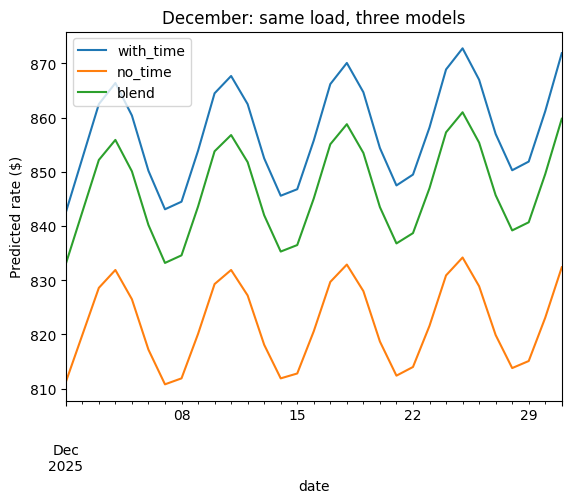

In [7]:
clean_all = tr[~tr["is_corrupted"]]
dec_inputs = cleaner.transform(dec.drop(columns="predicted_rate"), market_by_day)   # adds market_index by date

with_time = Hybrid(WITH_TIME).fit(clean_all)
no_time = Hybrid(NO_TIME).fit(clean_all)
blend = Blend([Hybrid(WITH_TIME), Hybrid(NO_TIME)], [0.7, 0.3]).fit(clean_all)

check = dec_inputs[["date", "market_index"]].copy()
check["with_time"] = with_time.predict(dec_inputs).round(1)
check["no_time"] = no_time.predict(dec_inputs).round(1)
check["blend"] = blend.predict(dec_inputs).round(1)
print(check.iloc[::3].to_string(index=False))
check.set_index("date")[["with_time", "no_time", "blend"]].plot(title="December: same load, three models", ylabel="Predicted rate ($)");